# Business Problem
A resort and city hotel are experiencing booking cancellations that lead to lost revenue, inaccurate demand forecasts, inefficient room allocation,
and poor planning for staffing and inventory.

The objective is to identify which types of bookings and customers are most likely to cancel, allowing the hotels to adjust policies, improve pricing
and deposit strategies, target the right market segments, and reduce lost revenue.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\more\Downloads\hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-2015


In [3]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [4]:
df=df.drop(columns=['meal','agent','arrival_date_week_number','arrival_date_day_of_month','company','reservation_status', 'reservation_status_date',
                    'reservation_status_year', "reservation_status_month"],
           errors="ignore")

In [5]:
df.isnull().sum()

hotel                               0
is_canceled                         0
lead_time                           0
arrival_date_year                   0
arrival_date_month                  0
stays_in_weekend_nights             0
stays_in_week_nights                0
adults                              0
children                            4
babies                              0
country                           488
market_segment                      0
distribution_channel                0
is_repeated_guest                   0
previous_cancellations              0
previous_bookings_not_canceled      0
reserved_room_type                  0
assigned_room_type                  0
booking_changes                     0
deposit_type                        0
days_in_waiting_list                0
customer_type                       0
adr                                 0
required_car_parking_spaces         0
total_of_special_requests           0
dtype: int64

In [6]:
df['children']=df['children'].fillna(0)
df['country']=df['country'].fillna("unknown")

In [7]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
dtype: int64

In [8]:
df.duplicated().sum()
df=df.drop_duplicates()

In [9]:
df=df[(df["adults"]+df["children"]+df["babies"])>0]

In [10]:
print(df[df["adr"] < 0][["adr", "hotel"]])

        adr         hotel
14969 -6.38  Resort Hotel


In [11]:
df = df[df["adr"] >= 0].copy()
print((df["adr"] < 0).sum())

0


In [12]:
df.shape

(86718, 25)

In [13]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly = (
    df.groupby("arrival_date_month")
      .agg(
          bookings=("is_canceled", "count"),
          cancellations=("is_canceled", "sum")
      )
      .reindex(month_order)
)

monthly["cancellation_rate"] = (
    monthly["cancellations"] / monthly["bookings"] * 100
)

print(monthly)

                    bookings  cancellations  cancellation_rate
arrival_date_month                                            
January                 4626           1023          22.114137
February                6020           1392          23.122924
March                   7439           1809          24.317785
April                   7859           2373          30.194681
May                     8296           2400          28.929605
June                    7722           2331          30.186480
July                   10016           3176          31.709265
August                 11198           3597          32.121807
September               6641           1607          24.198163
October                 6889           1619          23.501234
November                4938           1034          20.939652
December                5074           1361          26.823019


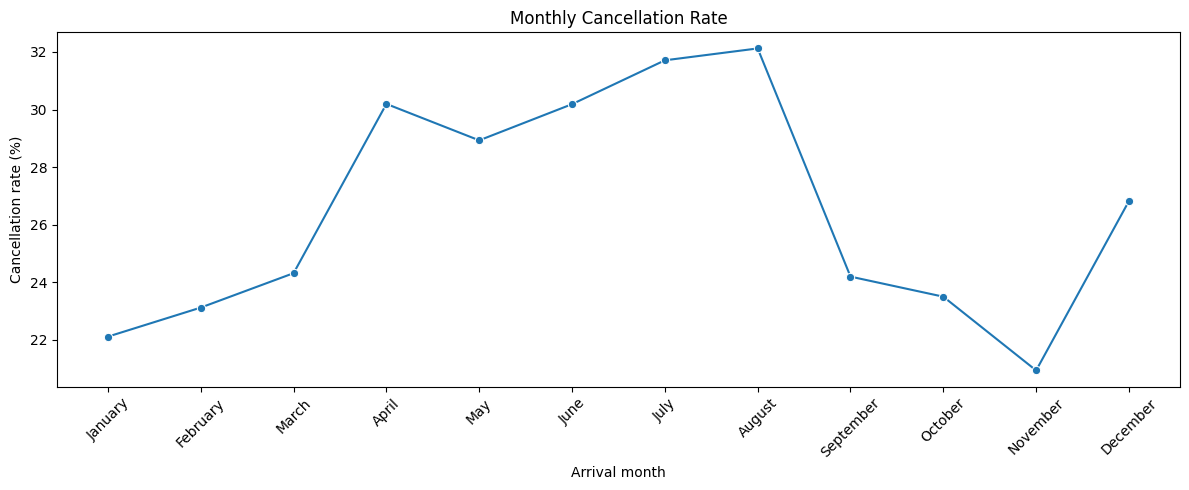

In [14]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly,
    x=monthly.index,
    y="cancellation_rate",
    marker="o"
)
plt.xticks(rotation=45)
plt.xlabel("Arrival month")
plt.ylabel("Cancellation rate (%)")
plt.title("Monthly Cancellation Rate")
plt.tight_layout()
plt.show()

### findings
- The highest cancellation rates occur during peak summer and late spring.
- November has the lowest cancellation rate.
- The summer period requires more reliable demand forecasting because cancellations create both missed occupancy and overbooking risk.
- **Recommendation**: Reconfirm summer bookings before arrival and use dynamic cancellation and deposit policies during high-risk months.

In [15]:
yearly = (
    df.groupby("arrival_date_year")
      .agg(
          bookings=("is_canceled", "count"),
          cancellations=("is_canceled", "sum")
      )
)

yearly["cancellation_rate"] = (
    yearly["cancellations"] / yearly["bookings"] * 100
)

print(yearly)

                   bookings  cancellations  cancellation_rate
arrival_date_year                                            
2015                  13184           2649          20.092536
2016                  42070          11071          26.315664
2017                  31464          10002          31.788711


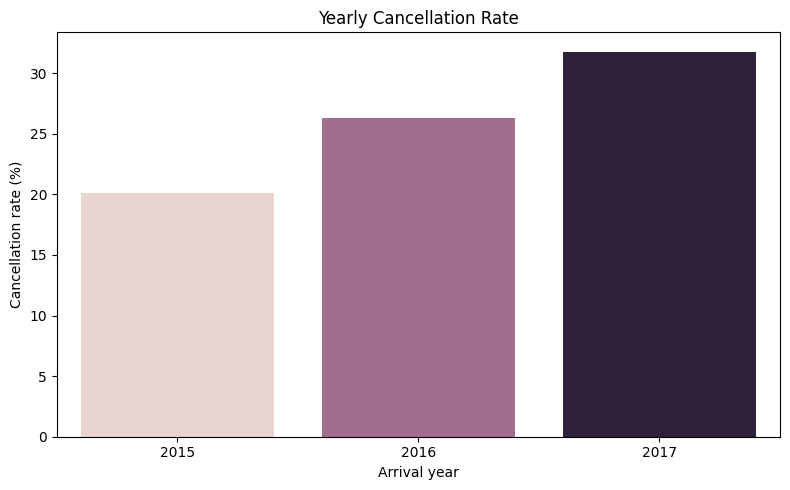

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=yearly.reset_index(),
    x="arrival_date_year",
    y="cancellation_rate",
    hue="arrival_date_year",
    legend=False
)
plt.xlabel("Arrival year")
plt.ylabel("Cancellation rate (%)")
plt.title("Yearly Cancellation Rate")
plt.tight_layout()
plt.show()

### Findings
- Cancellation rates increased each year.

**Business implication**: Historical data should not be used without considering the upward trend. Demand and cancellation forecasts should emphasize
more recent booking behavior.

In [17]:
total_night=df["total_nights"] = (
    df["stays_in_weekend_nights"]
    + df["stays_in_week_nights"]
)

total_guest=df["total_guests"] = (
    df["adults"] + df["children"] + df["babies"]
)
print(total_night.sum())
print(total_guest.sum())

315165
176083.0


In [18]:
nights_summary = (
    df.groupby("total_nights")
      .agg(
          bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
)
nights_summary["cancellation_rate"] *= 100
print(nights_summary) 

              bookings  cancellations  cancellation_rate
total_nights                                            
0                  584             23           3.938356
1                16941           3102          18.310607
2                15657           4142          26.454621
3                17736           5268          29.702300
4                13515           4099          30.329264
5                 6716           2038          30.345444
6                 3255           1118          34.347158
7                 7495           2286          30.500334
8                 1061            398          37.511781
9                  778            273          35.089974
10                1070            335          31.308411
11                 367            108          29.427793
12                 196             77          39.285714
13                 133             49          36.842105
14                 855            221          25.847953
15                  69         

In [19]:
df["night_group"] = pd.cut(
    df["total_nights"],
    bins=[-1, 2, 5, 7, 14, df["total_nights"].max()],
    labels=["0–2", "3–5", "6–7", "8–14", "15+"]
)
night_group_summary = (
    df.groupby("night_group", observed=True)
      .agg(
          bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
)
night_group_summary["cancellation_rate"] *= 100
print(night_group_summary)

             bookings  cancellations  cancellation_rate
night_group                                            
0–2             33182           7267          21.900428
3–5             37967          11405          30.039245
6–7             10750           3404          31.665116
8–14             4460           1461          32.757848
15+               359            185          51.532033


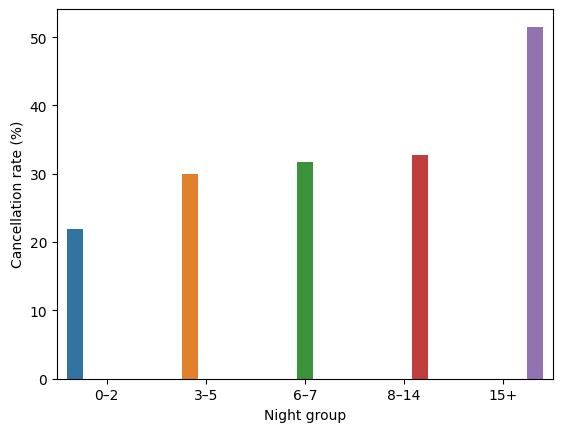

In [20]:
night_group_summary = night_group_summary.reset_index()

sns.barplot(
    data=night_group_summary,
    x="night_group",
    y="cancellation_rate",
    hue="night_group",
    legend=False
)
plt.ylabel("Cancellation rate (%)")
plt.xlabel("Night group")
plt.show()

### Findings:

- Cancellation risk generally increases with stay duration.
- Stays longer than 15 nights have the highest cancellation rate.
- Individual long stays, although fewer than short stays, create a high percentage of revenue uncertainty.

**Recommendations**:
- Require stricter cancellation terms or deposits for long stays.
- Review extended-stay bookings 30 to 60 days before arrival.
- Request a refundable deposit for 15+ night reservations.

In [21]:
customer_types = (
    df.groupby("customer_type")
      .agg(
          bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
)

customer_types["cancellation_rate"] *= 100
print(customer_types)

                 bookings  cancellations  cancellation_rate
customer_type                                              
Contract             3131            510          16.288726
Group                 541             53           9.796673
Transient           71494          21504          30.078049
Transient-Party     11552           1655          14.326524


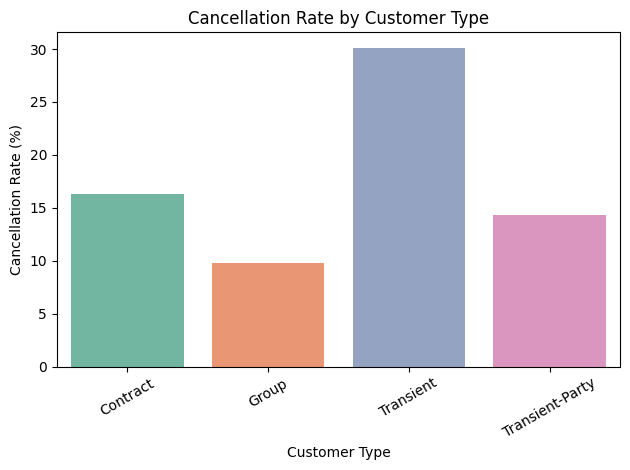

In [22]:

sns.barplot(
    data=customer_types,
    x="customer_type",
    y="cancellation_rate",
    hue="customer_type",
    palette="Set2",
    legend=False
)

plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Customer Type")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Findings:

- Transient customers account for most cancellations due to both their high cancellation rate and large booking volume.
- Group and contract bookings are relatively stable.
  
**Recommendations:**
- Prioritize cancellation prevention programs for transient customers.
- Send automated reminders and offers to encourage these guests to confirm or modify rather than cancel.
- Use flexible policies for stable contract and group customers only when business objectives support them.

In [23]:

avg_rate = (
    df.groupby("hotel", as_index=False)["adr"]
      .mean()
)
print(avg_rate)

          hotel         adr
0    City Hotel  111.361490
1  Resort Hotel   99.277959


In [24]:
adr_summary = (
    df.groupby("is_canceled")["adr"]
      .agg(["count", "mean", "median", "std"])
)
print(adr_summary)

             count        mean  median        std
is_canceled                                      
0            62996  102.336268    95.0  51.242928
1            23722  118.136706   109.8  62.228621


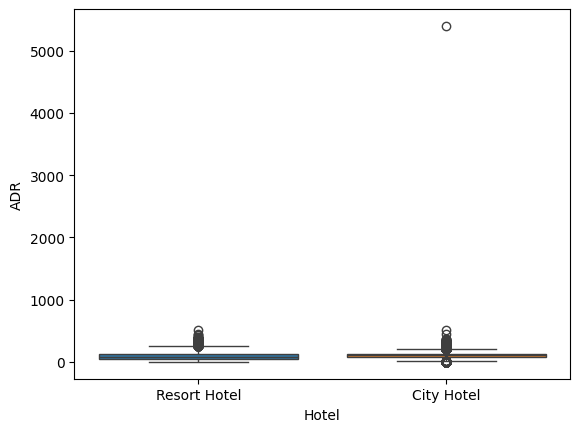

In [25]:

sns.boxplot(
    data=df,
    x="hotel",
    y="adr",
    hue="hotel",
    legend=False
)
plt.ylabel("ADR")
plt.xlabel("Hotel")
plt.show()

- Average ADR for City Hotel: 111.28
- Average ADR for Resort Hotel: 99.08
- Average ADR for completed bookings: 102.22
- Average ADR for canceled bookings: 117.86

### Findings:
- City Hotel rooms have a higher average daily rate.
- Canceled bookings have approximately 15.64 higher ADR on average.
- Higher-value reservations therefore represent a larger revenue-loss risk.
- 
 **Business implication:** Cancellation prevention should consider not only cancellation probability but also expected room revenue.

          hotel  is_canceled  cancellation_rate
0    City Hotel     0.299035          29.903525
1  Resort Hotel     0.233563          23.356345


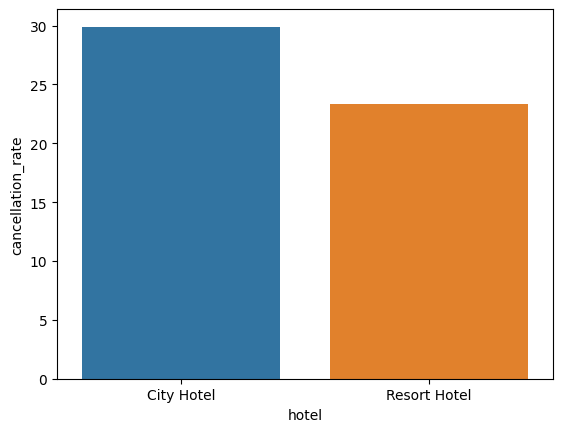

In [26]:
hotels_type=(
    df.groupby("hotel",as_index=False)['is_canceled'].mean()
)
hotels_type["cancellation_rate"]=hotels_type["is_canceled"]*100
print(hotels_type)

sns.barplot(x="hotel",
            y="cancellation_rate",
            data=hotels_type,
            hue='hotel')
plt.show() 

### Findings:
- City Hotel is more cancellation-prone.

**Business implication:** City Hotel should use stronger confirmation, deposit, and rebooking strategies, especially for high-risk segments.


  market_segment  is_canceled  cancellation_rate
0       Aviation     0.199115          19.911504
1  Complementary     0.123188          12.318841
2      Corporate     0.119730          11.973019
3         Direct     0.147079          14.707898
4         Groups     0.259037          25.903739
5  Offline TA/TO     0.145720          14.571989
6      Online TA     0.352700          35.269952
7      Undefined     1.000000         100.000000


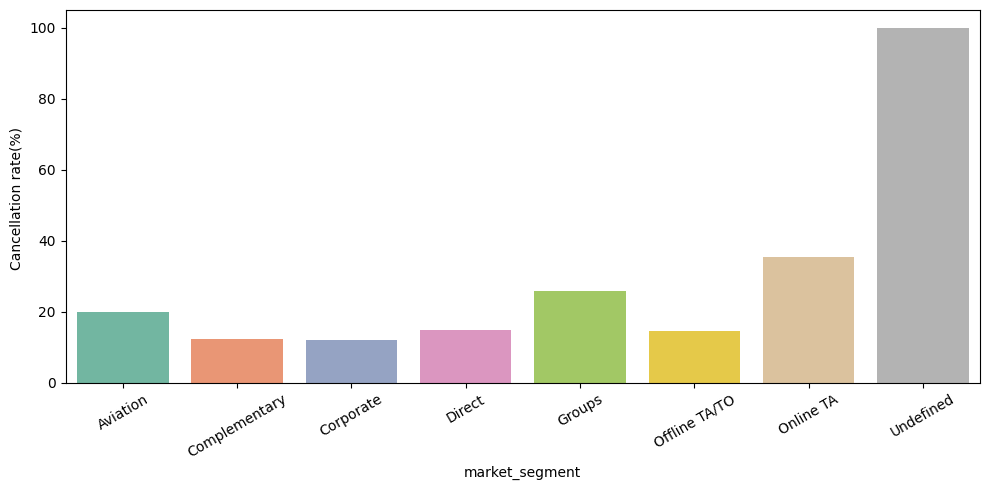

In [27]:

segment_df = (
    df.groupby("market_segment",as_index=False)["is_canceled"].mean()
)
segment_df["cancellation_rate"] = segment_df["is_canceled"] * 100
print(segment_df)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=segment_df,
    x="market_segment",
    y="cancellation_rate",
    hue="market_segment",
    palette="Set2",
    legend=False
)
plt.xticks(rotation=30)
plt.ylabel("Cancellation rate(%) ")
plt.tight_layout()
plt.show()

### Findings:
- Online Travel Agency bookings have the highest practical cancellation risk.
- Direct, corporate, and offline travel bookings are more stable.
- The Undefined segment should not be used as a meaningful business conclusion because it likely represents poor or incomplete data.

**Recommendations:**
- Track online-cancellation performance by individual OTA.
- Negotiate stronger booking and cancellation terms with high-cancellation channels.
- Encourage direct bookings through loyalty benefits, small discounts, or flexible rebooking.


In [28]:
city_hotel = df[df["hotel"] == "City Hotel"]

lead_mean = city_hotel.groupby("is_canceled")["lead_time"].mean()
print(lead_mean)

is_canceled
0     67.656513
1    101.337079
Name: lead_time, dtype: float64


### Findings:
- Canceled City Hotel reservations are typically booked significantly earlier.

**Business implication:** Long lead times create more opportunity for plans to change.

**Recommendation:** Use staged reminders and reconfirmation for bookings made more than 60 to 90 days before arrival.



In [29]:
deposit_rates = (
    city_hotel.groupby("deposit_type")["is_canceled"].mean()
)
print(deposit_rates * 100)

deposit_type
No Deposit    28.821396
Non Refund    97.111913
Refundable    66.666667
Name: is_canceled, dtype: float64


### Important finding:
- The high cancellation rate for Non Refund deposits appears counterintuitive. This may indicate these records include data-quality 
or category issues, or that such rates do not compare consistently with normal market behavior.

**Caution:** Do not immediately conclude that taking a deposit causes cancellations. A more reliable interpretation requires checking:
- Whether Non Refund deposits are mainly present in one hotel or customer segment.
- Whether the target variable is consistent with reservation status.
- Whether the 97.11% result is affected by a small sample.
- Whether cancellations may sometimes have generated a refund or reversal.
  
**Recommendation:** Investigate this result before changing the deposit strategy. Continue monitoring deposits using a complete cross-tabulation rather
than relying on the aggregate percentage.

### Key findings from the analysis:

- Overall, 27.68% of bookings were canceled, indicating significant revenue loss.
- City Hotel had a higher cancellation rate (29.90%) than Resort Hotel (23.49%).
- Transient customers canceled the most, with a 30.08% cancellation rate.
- Online Travel Agency bookings had the highest cancellation rate at 35.39%, followed by Group bookings at 27.08%.
- Cancellation rates increased over time, from 20.09% in 2015 to 31.79% in 2017.
- August had the highest monthly cancellation rate at 32.12%, followed by July at 31.71%.
- Bookings lasting 15 or more nights had the highest cancellation rate of 51.53%.
- Canceled City Hotel bookings had a longer average lead time—101.65 days—than completed bookings at 67.51 days.
- Canceled reservations had a higher average ADR of 118.14, compared with 102.34 for completed reservations.

**Business conclusion:** The hotels should introduce stronger confirmation and deposit policies for transient, online, long-stay, and high-advance bookings,especially at City Hotel during peak summer months.